# 05 · LLM post-processing

Even good recognizers leave character errors: a wrong letter, a missing accent, a split word.
A language model that knows early-modern Spanish *and* how OCR fails can fix them from context.

* Off-the-shelf (zero-shot) LLMs made results **worse**: they modernize spelling and rewrite.
* So we **fine-tuned** two open 4B models with QLoRA on real (OCR line → truth) pairs:
  `google/gemma-3-4b-it` (shipped in the app) and `Qwen/Qwen3-4B-Instruct-2507`.
* Both correct **one line at a time** and must return it unchanged when it is already right.

The same book-level split holds out the same 3 books from both the recognizers and the correctors.

In [1]:
# Make experimentation/src importable (this also puts backend/ on sys.path, so the
# notebooks run the app's own preprocessing, detection and recognition code).
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
%matplotlib inline

In [2]:
import json, pandas as pd
from src import figures
from src.llm_finetune import SYSTEM_PROMPT, load_pairs, split_pairs
from src.metrics import cer
from src.paths import CHECKPOINTS

pairs = load_pairs()
train, val = split_pairs(pairs)
print(f"{len(pairs)} pairs | train {len(train)} | val {len(val)} (held-out books: {sorted(val.doc_id.unique())})")
pd.DataFrame({src: {"lines": len(d), "raw OCR CER": f"{cer(list(d['ocr']), list(d['gt'])):.2%}",
                    "perfect lines": f"{(d['ocr'] == d['gt']).mean():.0%}"}
              for src, d in pairs.groupby("source")}).T

7614 pairs | train 5912 | val 1702 (held-out books: ['Buendia - Instruccion', 'PADILLA 1 Nobleza Virtuosa 1637', 'PORCONES.200.2 ÔÇô 1670'])


,lines,raw OCR CER,perfect lines
crnn,3807,1.55%,63%
paddle,3807,14.61%,8%


In [3]:
print("System prompt:\n", SYSTEM_PROMPT, "\n")
for _, r in pairs[pairs['ocr'] != pairs['gt']].sample(6, random_state=0).iterrows():
    print(f"[{r.source}] OCR  : {r['ocr']}\n         truth: {r['gt']}\n")

System prompt:
 You are an expert in early-modern Spanish (15th-19th century) palaeography and OCR correction. The user gives you one raw OCR line from a historical Spanish document. Return ONLY the corrected line, nothing else. Fix glyph confusions (rn→m, 0→o, 1/I→l, ſ→s), restore diacritics (á é í ó ú ñ ç), and merge or split wrongly tokenised words. Preserve the original early-modern spelling: never modernise, translate, or add content. If the line is already correct, return it unchanged. 

[crnn] OCR  : el Propheta; ni permitireys os ha-8.
         truth: el Propheta; ni permitireys os ha-

[paddle] OCR  : ramente la dicha dona Mariana dize, como el di-
         truth: ramente la dicha doña Mariana dize, como el di-

[crnn] OCR  : 1.2u. num.3.ff.ad l. Iul de adult. Está sin embargo
         truth: 1.2…num.3.ff.ad l Iul de adult. Está sin embargo

[paddle] OCR  : Acudireys a las proceſſiones, imi-
         truth: Acudireys a las processiones, imi-

[paddle] OCR  : Pablo , que no lle

**Where the pairs come from.** Every corpus line was read by two engines: the stock
PaddleOCR `latin_PP-OCRv5_mobile_rec` (noisy, many errors to learn from) and our first CRNN
(mostly clean, which teaches the model to leave correct lines alone):

```python
from paddleocr import TextRecognition
rec = TextRecognition(model_name="latin_PP-OCRv5_mobile_rec")
ocr = [r["rec_text"] for r in rec.predict(input=line_images, batch_size=32)]
```

## QLoRA fine-tuning

The base model is frozen in 4-bit NF4 (double quantization, bf16 compute). Small rank-16 LoRA
adapters on every attention and MLP projection are trained (~33 M parameters, under 1% of 4 B),
with learning rate 2e-4 (cosine), effective batch 16, and early stopping on validation loss
every 100 steps. Gemma was trained on Kaggle (2× T4); Qwen fits a local 8 GB GPU.

To re-run on Kaggle: upload `experimentation/` (with `data/postprocess_pairs/`) as a dataset,
add it to a GPU T4 ×2 notebook with internet on, put this folder on `sys.path`, and set an
`HF_TOKEN` secret (Gemma is gated).

In [4]:
RUN_TRAINING = False   # ~1 h per model; the trained adapters are in checkpoints/postprocess/
if RUN_TRAINING:
    from src.llm_finetune import QLoRAFineTuner
    QLoRAFineTuner("google/gemma-3-4b-it", CHECKPOINTS / "postprocess" / "gemma-3-4b-it-lora").train(train, val)

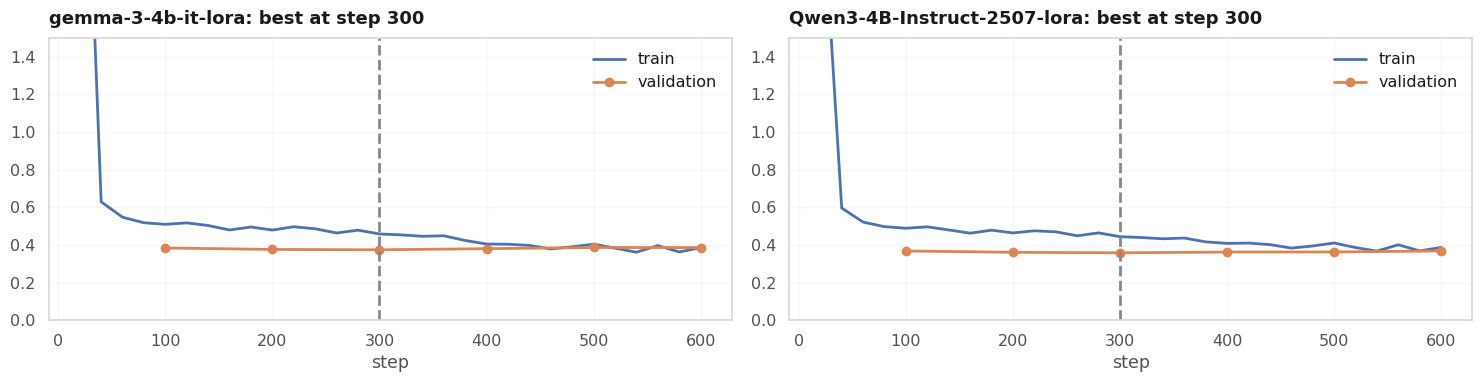

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, name in zip(axes, ("gemma-3-4b-it-lora", "Qwen3-4B-Instruct-2507-lora")):
    log = json.loads((CHECKPOINTS / "postprocess" / name / "trainer_state.json").read_text())["log_history"]
    ax.plot([x["step"] for x in log if "loss" in x], [x["loss"] for x in log if "loss" in x], label="train")
    ev = [x for x in log if "eval_loss" in x]
    ax.plot([x["step"] for x in ev], [x["eval_loss"] for x in ev], "o-", label="validation")
    best = min(ev, key=lambda x: x["eval_loss"])
    ax.axvline(best["step"], color="#888", ls="--"); ax.set_ylim(0, 1.5)
    ax.set_title(f"{name}: best at step {best['step']}"); ax.set_xlabel("step"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()

Both runs stopped early: validation loss was lowest after ~300 steps (about 0.8 epoch) and
rose afterwards, so the saved adapters are the step-300 weights.

## The original evaluation (400 held-out lines from the pair data)

Zero-shot models made things worse; fine-tuning nearly halved the word error rate.

In [6]:
orig = json.loads((CHECKPOINTS / "postprocess" / "results.json").read_text())
pd.DataFrame(orig).T.style.format("{:.2%}")

,cer,wer
raw OCR,4.65%,20.92%
Qwen3-4B-Instruct-2507 (zero-shot),6.67%,22.87%
Qwen3-4B-Instruct-2507 (fine-tuned),3.46%,12.18%
gemma-3-4b-it (zero-shot),6.60%,21.46%
gemma-3-4b-it (fine-tuned),3.20%,11.46%


## On the retrained recognizers

The adapters were trained on errors of the *previous* CRNN and of PaddleOCR. Here they correct
the outputs of the **new** CRNN and TrOCR, on the 851 validation lines and on the 28 test
pages (preprocessed), from `scripts/evaluate.py correct gemma|qwen`.

In [7]:
res = figures.results()
rows = {}
for model in ("CRNN", "TrOCR"):
    for suffix in ("", " + gemma", " + qwen"):
        r = res.get(model + suffix)
        if r:
            rows[model + suffix] = {"line CER": r["line"]["cer"], "line WER": r["line"]["wer"],
                                    "page CER": r["page_cleaned"]["cer"], "page WER": r["page_cleaned"]["wer"]}
pd.DataFrame(rows).T.style.format("{:.2%}")

,line CER,line WER,page CER,page WER
CRNN,1.64%,7.31%,14.17%,35.91%
CRNN + gemma,1.94%,7.83%,17.60%,37.57%
CRNN + qwen,1.99%,7.76%,16.51%,35.63%
TrOCR,2.57%,10.54%,11.82%,27.58%
TrOCR + gemma,3.03%,10.68%,12.54%,28.56%
TrOCR + qwen,2.95%,10.81%,12.70%,28.12%


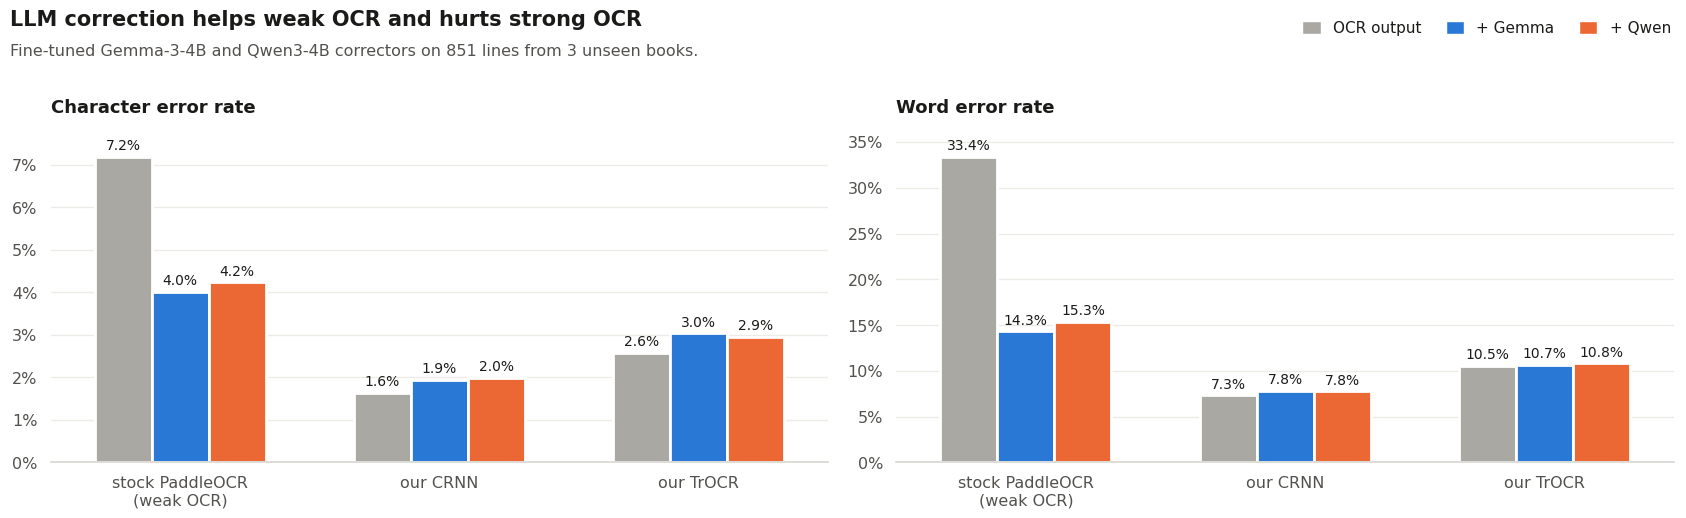

In [8]:
figures.postprocessing_gain();

In [9]:
from src.corpus import LineCorpus

_, lines = LineCorpus().split()
raw, fixed = figures.predictions("TrOCR")["lines"], figures.predictions("TrOCR + gemma")["lines"]
changed = [(r, f, t) for r, f, t in zip(raw, fixed, lines.text) if r != f]
better = sum(cer([f], [t]) < cer([r], [t]) for r, f, t in changed)
worse = sum(cer([f], [t]) > cer([r], [t]) for r, f, t in changed)
print(f"Gemma changed {len(changed)} of {len(raw)} TrOCR lines: {better} better, {worse} worse\n")
for r, f, t in changed[:8]:
    print(f"OCR  : {r}\nfixed: {f}\ntruth: {t}\n")

Gemma changed 158 of 851 TrOCR lines: 48 better, 92 worse

OCR  : 'A L
fixed: A DON ALONSO PEREZ
truth: Al

OCR  : NINO yESUS.
fixed: NINO y JESUS.
truth: NIÑO JESUS.

OCR  : Vos, Dulcissimo Nifo
fixed: Vos, Dulcissimo Niño
truth: A Vos, Dulcissimo Niño

OCR  : JEsvs, que no solo os Exisai.33.
fixed: Es vna cosa tan cierta, que no solo os Exista, 33.
truth: JESUS, que no solo os

OCR  : tir como Níño entre los Doctores,
fixed: tir como Niño entre los Doctores,
truth: tir como Niño entre los Doctores,

OCR  : guro dissenño de su edad: la Reli-
fixed: guero diseño de su edad: la Reli-
truth: guro disseño de su edad: la Reli-

OCR  : el disseno, la luz, y el exemplo,
fixed: el diseño, la luz, y el ejemplo,
truth: el disseño, la luz, y el exemplo,

OCR  : dimiento, y comunicis la sabi-
fixed: dimento, y comunicis la sabi-
truth: dimiento, y comunicais la sabi-

